<a href="https://colab.research.google.com/github/VanshikaJain2105/House-Price-Prediction/blob/main/House_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# House Price Prediction

**Goal:** Predict historical Boston-area neighborhood median house values and learn a complete regression workflow.

**What we will be doing:** dataset auditing, exploratory data analysis, feature/target splitting, regression baselines, pipelines, 5-fold cross-validation, model comparison, hyperparameter tuning, error analysis, feature importance

## Import libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 30)

In [4]:
df = pd.read_csv("/content/BostonHousing.csv")
df.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [6]:
print("rows, columns:", df.shape)

rows, columns: (506, 14)


### What do the columns mean?
- **rm**: average number of rooms per dwelling
- **lstat**: percentage of population classified as lower status in the original historical dataset (an outdated socioeconomic measure)
- **ptratio**: pupil–teacher ratio by town
- **crim**: per-capita crime rate by town
- **nox**: nitric-oxide concentration
- **chas**: 1 if tract bounds the Charles River; otherwise 0
- **medv**: **target** median owner-occupied housing value in $1000s

Other predictors are zn, indus, age, dis, rad, tax. The b feature is an inappropriate race-derived variable: **we will not use it**

##Understanding and Cleaning data

In [7]:
print("Column types and non-null counts:")
df.info()

Column types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  b        506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


In [10]:
print("\nMissing values by column:")
display(df.isna().sum())


Missing values by column:


,0
crim,0
zn,0
indus,0
chas,0
nox,0
rm,0
age,0
dis,0
rad,0
tax,0


In [11]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [16]:
df["medv"].max()

50.0

In [15]:
# Checking how many records have the maximum reported house value
print("Number of records with capped prices:", (df["medv"] == 50).sum())

Number of records with capped prices: 16


## Exploratory Data Analysis (EDA)
**Why?** EDA helps us understand typical prices, outliers, and the relationships between features and price

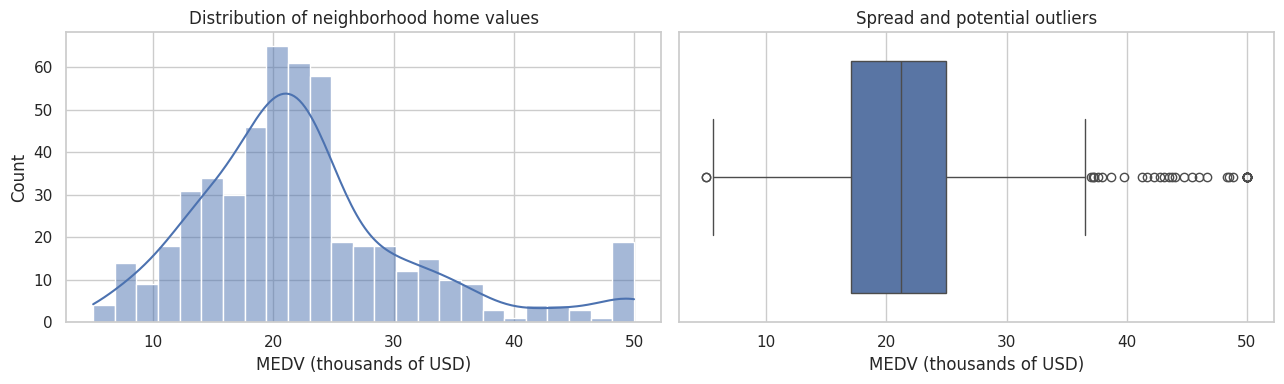

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["medv"], bins=25, kde=True, ax=axes[0])
axes[0].set(title="Distribution of neighborhood home values", xlabel="MEDV (thousands of USD)")
sns.boxplot(x=df["medv"], ax=axes[1])
axes[1].set(title="Spread and potential outliers", xlabel="MEDV (thousands of USD)")
plt.tight_layout()
plt.show()

The histogram shows where most neighborhood values cluster

The boxplot highlights unusually low/high values



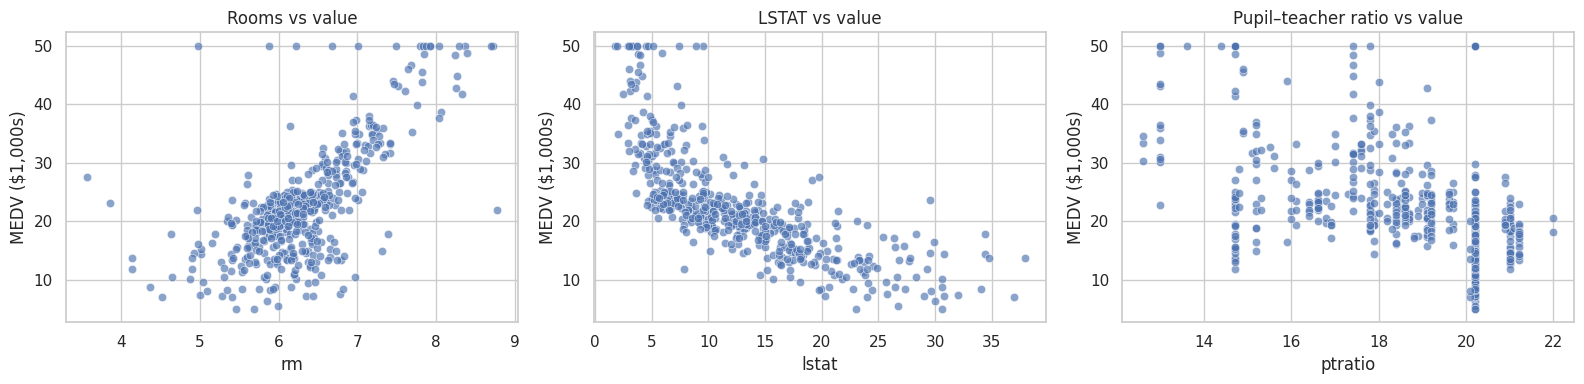

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
#plotting three scatterplot using loop
for ax, feature, title in zip(axes, ["rm", "lstat", "ptratio"],["Rooms vs value", "LSTAT vs value", "Pupil–teacher ratio vs value"]):
    sns.scatterplot(data=df, x=feature, y="medv", alpha=0.65, ax=ax)
    ax.set_title(title)
    ax.set_ylabel("MEDV ($1,000s)")

plt.tight_layout()
plt.show()

**1. Rooms vs House Price (rm)**
- As the number of rooms increases, house prices generally increase
- Positive correlation: More rooms → Higher price

**2. LSTAT vs House Price (lstat)**
- lstat represents the percentage of the population classified as lower socioeconomic status in the historical dataset
- As LSTAT increases, house prices generally decrease
- Negative correlation: Higher LSTAT → Lower price

**3. Pupil–Teacher Ratio vs House Price (ptratio)**
- A higher ratio means more students per teacher
- Areas with higher ratios generally have lower house values
- Weak negative correlation: Higher ratio → Generally lower price, but the relationship isn't very strong

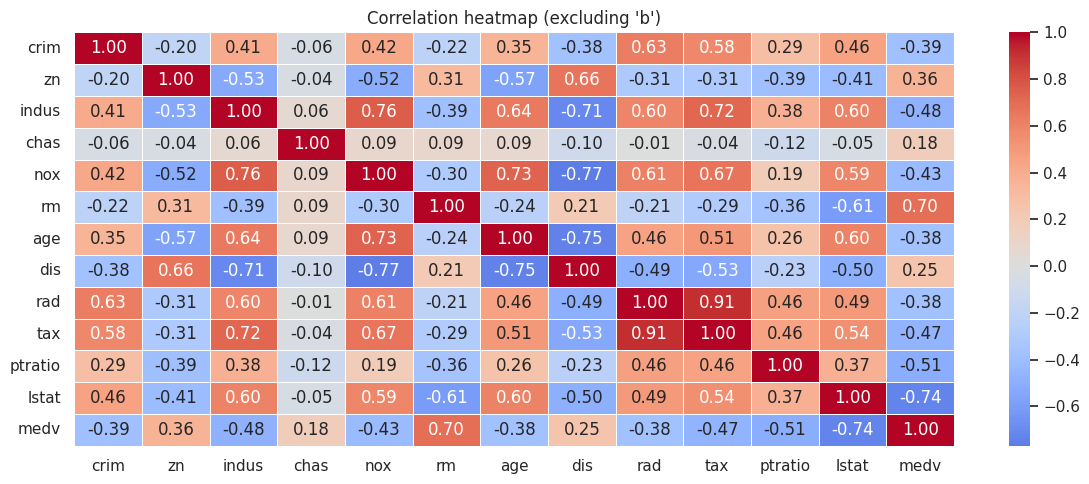

In [24]:
# Exclude the race-derived column even from this analysis.
analysis_df = df.drop(columns=["b"], errors="ignore")
correlations = analysis_df.corr(numeric_only=True)
plt.figure(figsize=(12, 5))
sns.heatmap(correlations, cmap="coolwarm", center=0, annot=True, fmt=".2f", linewidths=0.4)
plt.title("Correlation heatmap (excluding 'b')")
plt.tight_layout()
plt.show()


In [27]:
display(correlations["medv"].drop("medv").sort_values(key=abs, ascending=False))

,medv
lstat,-0.737663
rm,0.695360
ptratio,-0.507787
indus,-0.483725
tax,-0.468536
nox,-0.427321
crim,-0.388305
rad,-0.381626
age,-0.376955
zn,0.360445


**Why the heatmap?** Correlation summarizes the direction/strength of a **linear** relationship (near +1 positive, near −1 negative, near 0 weak linear association).

Conclusion: rm and lstat have the strongest linear relationships with house prices among the features shown

In [28]:
# Separating features and target variable
X = df.drop(columns=["medv", "b"])
y = df["medv"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (506, 12)
y shape: (506,)


In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)

## Build preprocessing + model pipelines
**Why imputation?** Replaces a missing numeric feature with the **training-fold median** if one appears

**Why scaling?** Linear Regression works well with standardized numeric inputs; tree ensembles don't need scaling. Pipelines learn every transformation on training folds only, preventing data leakage

We add a **dummy baseline** that always predicts the training median. A useful ML model should perform substantially better than this simple guess

In [31]:
# Initializing regression models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

In [35]:
models["Baseline"] = DummyRegressor(strategy="median")

A Dummy Regressor is a very simple model that doesn't actually learn relationships between features and house prices

Instead, it predicts the same value for every house

## Cross-validation: compare models fairly
**Why?** One train/validation split can be lucky or unlucky. In 5-fold CV, each model is trained five times, using a different portion of the **training set** for validation. We average the results.

- **MAE** = average absolute prediction error; lower is better
- **RMSE** = square-root of mean squared error; penalizes large errors more; lower is better
- **R²** = fraction of target variation explained relative to predicting its mean; higher is better, can be negative

MAE and RMSE here are in **$1000s**, not dollars

In [37]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

results = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    results.append({
        "Model": name,
        "CV MAE": -scores["test_mae"].mean(),
        "CV RMSE": -scores["test_rmse"].mean(),
        "CV R²": scores["test_r2"].mean(),
        "RMSE Std": scores["test_rmse"].std(),
    })

#This loop trains and evaluates every model using the same 5-fold cross-validation process

In [38]:
#This puts the models with the lowest average prediction error at the top
comparison = pd.DataFrame(results).sort_values("CV RMSE").reset_index(drop=True)
display(comparison.round(3))


,Model,CV MAE,CV RMSE,CV R²,RMSE Std
0,Gradient Boosting,2.318,3.556,0.847,0.630
1,Random Forest,2.380,3.718,0.833,0.556
2,Linear Regression,3.558,4.974,0.707,0.752
3,Decision Tree,3.071,5.252,0.642,1.003
4,Baseline,6.696,9.363,-0.024,0.917


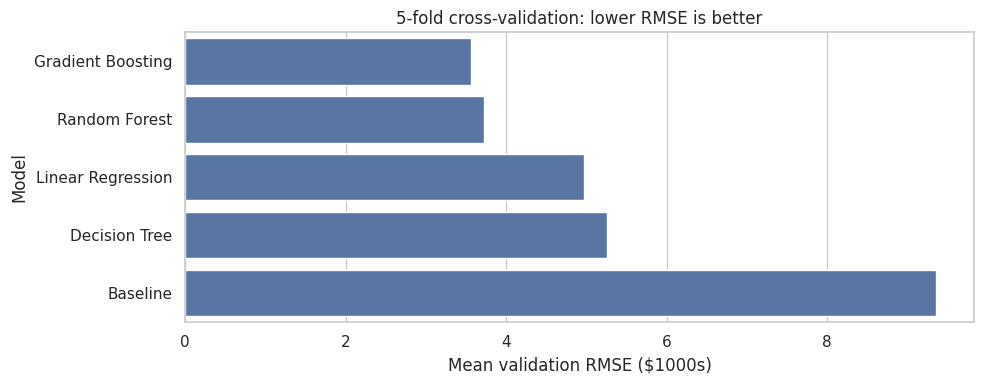

In [40]:
plt.figure(figsize=(10, 4))
sns.barplot(data=comparison, x="CV RMSE", y="Model")
plt.title("5-fold cross-validation: lower RMSE is better")
plt.xlabel("Mean validation RMSE ($1000s)")
plt.tight_layout()

plt.show()

In [41]:
print("Best untuned model by CV RMSE:", comparison.loc[0, "Model"])

Best untuned model by CV RMSE: Gradient Boosting


## Tune hyperparameters (training data only)

**Why?** Settings such as tree depth and the number of trees control model complexity. **GridSearchCV** tries several combinations and scores each with CV, instead of guessing

We tune a **Random Forest** as a learning exercise. Afterwards we'll compare it against the best untuned model by cross-validation, so tuning doesn't automatically win

In [44]:
# Hyperparameter tuning for Random Forest
rf = RandomForestRegressor(random_state=42)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 8, 14],
    "min_samples_leaf": [1, 2, 4]
}

search = GridSearchCV(rf,param_grid,scoring="neg_root_mean_squared_error",cv=cv,n_jobs=-1)

search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best CV RMSE:", -search.best_score_)

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV RMSE: 3.7017248682083084


## Select the model and evaluate once on untouched test data
**Why?** We choose by **validation performance**, not by test performance. The selected model is then fit on all training data and tested only once. This gives a more honest estimate of generalization

Note: the tuned forest uses the same CV folds that selected its parameters, so its best_score_ is somewhat optimistic. A larger project would use nested CV or a separate validation set. The final held-out test remains untouched by selection.

In [46]:
best_untuned_name = comparison.loc[0, "Model"]
best_untuned_rmse = comparison.loc[0, "CV RMSE"]
tuned_rf_rmse = -search.best_score_

if tuned_rf_rmse < best_untuned_rmse:
    final_name = "Tuned Random Forest"
    final_model = search.best_estimator_
else:
    final_name = best_untuned_name
    final_model = models[best_untuned_name].fit(X_train, y_train)

# GridSearchCV(refit=True) already refits the selected RF on the full training set.
y_pred = final_model.predict(X_test)
test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_r2 = r2_score(y_test, y_pred)

print("Selected model:", final_name)
print(f"Held-out test MAE : {test_mae:.3f} ($1000s)")
print(f"Held-out test RMSE: {test_rmse:.3f} ($1000s)")
print(f"Held-out test R²  : {test_r2:.3f}")
print(f"Approximate MAE in historical dollars: ${test_mae * 1000:.0f}")

Selected model: Gradient Boosting
Held-out test MAE : 1.905 ($1000s)
Held-out test RMSE: 2.496 ($1000s)
Held-out test R²  : 0.915
Approximate MAE in historical dollars: $1905


## Inspect predictions and errors
**Why?** One accuracy number can hide problems. An actual-vs-predicted plot shows whether predictions follow the diagonal; a residual plot helps reveal bias and large mistakes.

**Residual = actual − predicted**. Positive residual = model predicted too low

Negative = predicted too high

In [47]:
evaluation = pd.DataFrame({
    "Actual ($1000s)": y_test.to_numpy(),
    "Predicted ($1000s)": y_pred,
})
evaluation["Residual"] = evaluation["Actual ($1000s)"] - evaluation["Predicted ($1000s)"]
evaluation["Absolute Error"] = evaluation["Residual"].abs()
display(evaluation.head(10).round(2))


,Actual ($1000s),Predicted ($1000s),Residual,Absolute Error
0,23.6,23.41,0.19,0.19
1,32.4,31.04,1.36,1.36
2,13.6,16.29,-2.69,2.69
3,22.8,23.74,-0.94,0.94
4,16.1,16.71,-0.61,0.61
5,20.0,22.14,-2.14,2.14
6,17.8,18.09,-0.29,0.29
7,14.0,14.16,-0.16,0.16
8,19.6,20.31,-0.71,0.71
9,16.8,20.83,-4.03,4.03


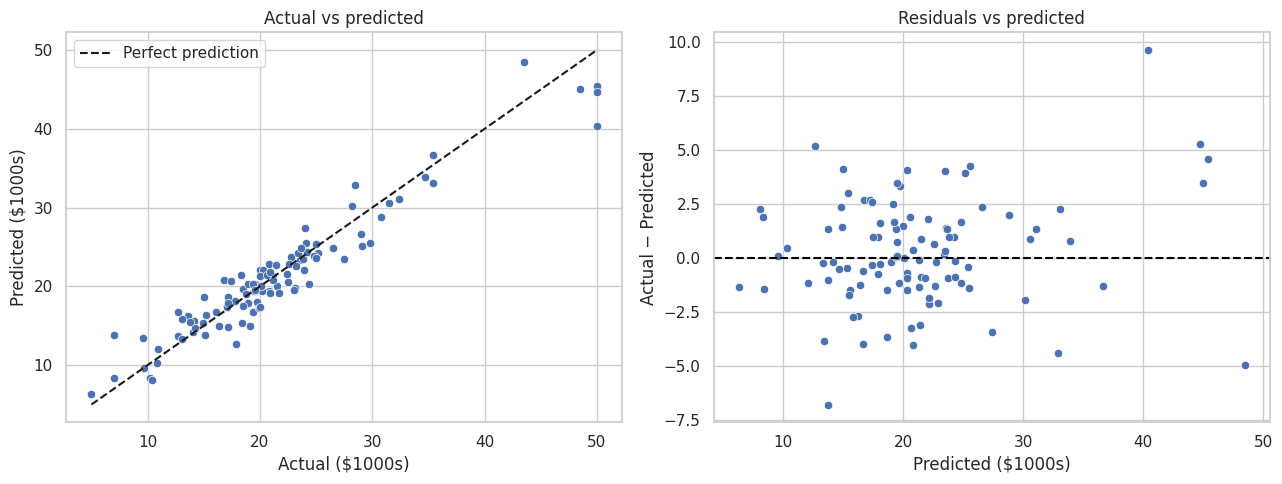

Five largest absolute errors:


,Actual ($1000s),Predicted ($1000s),Residual,Absolute Error
96,50.0,40.37,9.63,9.63
79,7.0,13.78,-6.78,6.78
42,50.0,44.71,5.29,5.29
97,17.9,12.70,5.20,5.20
54,43.5,48.45,-4.95,4.95


In [52]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=evaluation, x="Actual ($1000s)", y="Predicted ($1000s)", ax=axes[0])
lims = [min(evaluation.iloc[:, :2].min()), max(evaluation.iloc[:, :2].max())]
axes[0].plot(lims, lims, "k--", label="Perfect prediction")
axes[0].legend()
axes[0].set_title("Actual vs predicted")
sns.scatterplot(data=evaluation, x="Predicted ($1000s)", y="Residual", ax=axes[1])
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(title="Residuals vs predicted", ylabel="Actual − Predicted")
plt.tight_layout()
plt.show()

print("Five largest absolute errors:")
display(evaluation.sort_values("Absolute Error", ascending=False).head().round(2))

## What features does the final model rely on?

**Why?** Permutation importance measures how much test-set prediction quality worsens when we randomly shuffle one feature. Bigger increases in error suggest the model relies more on that feature.


In [55]:
importance = permutation_importance(
    final_model, X_test, y_test, n_repeats=15,
    random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error"
)

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "RMSE increase when shuffled": importance.importances_mean,
    "Std": importance.importances_std,
}).sort_values("RMSE increase when shuffled", ascending=False)

display(importance_df.round(3))


,Feature,RMSE increase when shuffled,Std
11,lstat,4.546,0.545
5,rm,3.371,0.156
7,dis,1.373,0.360
4,nox,0.847,0.243
10,ptratio,0.526,0.119
0,crim,0.443,0.097
6,age,0.417,0.093
9,tax,0.093,0.047
2,indus,0.033,0.012
8,rad,0.028,0.029


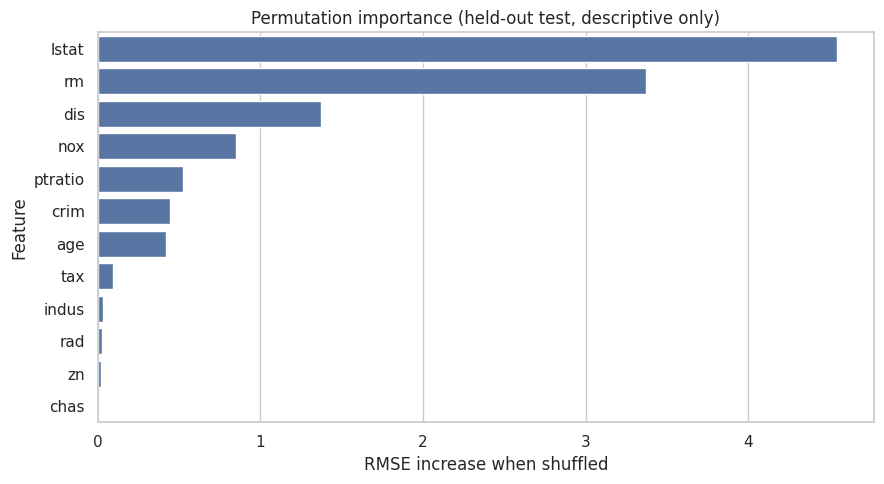

In [56]:
plt.figure(figsize=(9, 5))

sns.barplot(data=importance_df, x="RMSE increase when shuffled", y="Feature")
plt.title("Permutation importance (held-out test, descriptive only)")
plt.tight_layout()

plt.show()

## Predict an unseen example

**Why?** We want to make sure the **entire pipeline** can predict from a correctly structured row.

In [57]:
sample_house = X_test.iloc[[0]].copy()  # preserve original feature names/order
sample_prediction = final_model.predict(sample_house)[0]
print("Example features:")
display(sample_house)

Example features:


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat
173,0.09178,0.0,4.05,0,0.51,6.416,84.1,2.6463,5,296,16.6,9.04


In [59]:
print(f"Predicted neighborhood median value: {sample_prediction:.2f} × $1000")
print(f"Equivalent historical-dollar figure: ${sample_prediction * 1000:.0f}")
print(f"Recorded target for comparison: ${y_test.iloc[0] * 1000:.0f}")

Predicted neighborhood median value: 23.41 × $1000
Equivalent historical-dollar figure: $23406
Recorded target for comparison: $23600


In [61]:
print(f"Predicted house value: ${sample_prediction * 1000:.2f}")

Predicted house value: $23405.73


## Learnings
1. This is a **regression** problem: our target is numeric, not a class label
2. **EDA** helps us detect patterns, unusual values, and dataset limitations before modeling.
3. A **baseline** shows whether machine learning beats a simple guess.
4. **Pipelines + cross-validation** give fairer comparisons without preprocessing leakage.
5. **Hyperparameter tuning** can improve models, but only the held-out test estimates final generalization
6. **MAE, RMSE, and R²** measure different aspects of error
7. **Residuals and feature importance** help us understand how a model behaves, not just its score

=================Thankyouuu=======================